# 04. Протокол расширения пилота METAR

## 1. Цель и область исследования

Цель следующего этапа — проверить переносимость процедуры сопоставления и
декодирования на дополнительные станции. Протокол фиксируется до загрузки
новых сообщений METAR и оценки их покрытия. Это техническое исследование;
выборка не является вероятностной и не обеспечивает репрезентативность Европы.
Обучение модели и исключение записей не входят в этот этап.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
protocol=json.loads((R/'07_expansion_protocol.json').read_text(encoding='utf8'))
airports=pd.read_csv(R/'01_airport_coverage.csv')
counts=pd.read_csv(R/'07_c40_month_counts.csv')
assert protocol['input_sha256']==manifest['input_sha256']
selected=protocol['selected_airports']
ranked=airports.sort_values(['c40_early','airport'],ascending=[False,True])
assert ranked.loc[~ranked.airport.isin(protocol['previous_airports'])].head(3).airport.tolist()==selected
display(ranked[['airport','rows','c40_early']].assign(
    stage=ranked.airport.map(lambda a:'Расширение' if a in selected else ('Первый пилот' if a in protocol['previous_airports'] else 'Вне пилота'))))


,airport,rows,c40_early,stage
0,EGLL,631718,631718,Первый пилот
1,LFPG,617562,617562,Первый пилот
2,EDDF,604960,604960,Расширение
3,EHAM,561481,561481,Расширение
4,LEMD,515044,515044,Расширение
5,EDDM,443203,443203,Вне пилота
6,LIRF,322749,322749,Вне пилота
7,LSZH,316973,316973,Вне пилота
8,LOWW,293578,293578,Вне пилота
9,EIDW,263879,263879,Вне пилота


## 2. Критерий выбора станций

Включаются три ранее не исследованных аэропорта с наибольшим числом записей
с C40 не позже первой попытки; при равенстве применяется алфавитный порядок
ICAO. Частота GoA и погодные характеристики в ранжировании не участвуют.
Германия, Нидерланды и Испания расширяют географию станций. При этом страна
не является доказательством отличий в единицах или структуре METAR.
Отбор по объему смещает исследование в сторону крупных аэропортов.


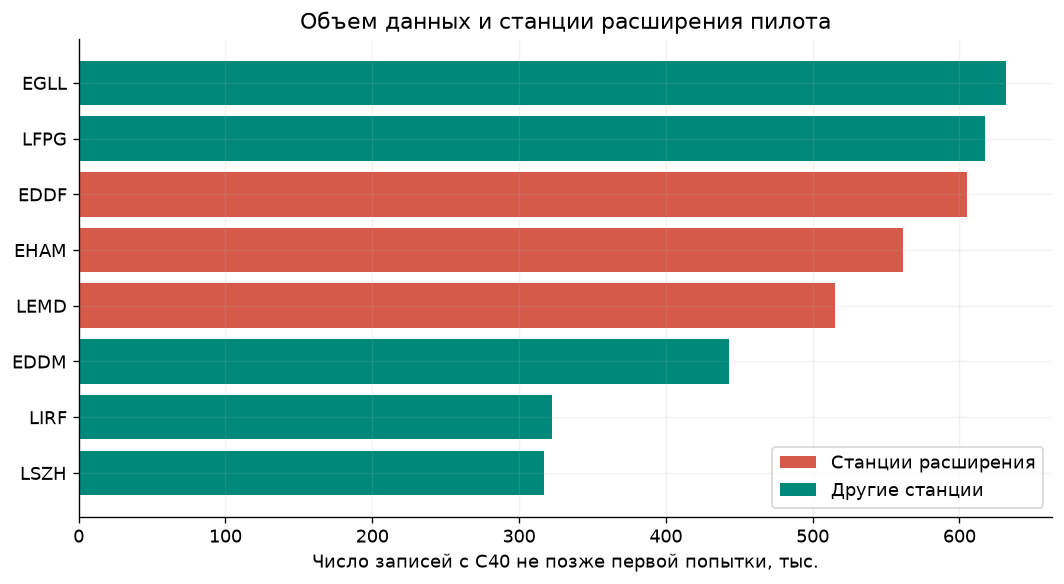

In [3]:
from matplotlib.patches import Patch
top=ranked.head(8).sort_values('c40_early')
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(top.airport,top.c40_early/1000,color=[CORAL if a in selected else GREEN for a in top.airport])
ax.set(xlabel='Число записей с C40 не позже первой попытки, тыс.',title='Объем данных и станции расширения пилота')
ax.legend(handles=[Patch(facecolor=CORAL,label='Станции расширения'),Patch(facecolor=GREEN,label='Другие станции')],loc='lower right')
save('11_expansion_station_selection')


## 3. Проверка метаданных станций

Проверяется наличие единственного идентификатора станции в соответствующей
сети IEM. Сохраняются байты GeoJSON, URL, SHA256 и время загрузки. Координаты
и название приводятся как метаданные источника, без утверждения о независимой
геодезической верификации. Метаданные описывают текущее состояние каталога;
дата начала архива не подтверждает непрерывное покрытие METAR в 2019 году.
Соответствие кода внутри каждого сообщения будет проверено после загрузки.


In [4]:
metadata=[]
for source in protocol['station_metadata']:
    path=DATA/'station_metadata'/f"{source['network']}.geojson"
    assert sha(path)==source['sha256']
    item=[f for f in json.loads(path.read_text(encoding='utf8'))['features'] if f['id']==source['station']]
    assert len(item)==1
    p=item[0]['properties']
    metadata.append(dict(station=source['station'],network=source['network'],name=p.get('sname'),
        longitude=source['coordinates'][0],latitude=source['coordinates'][1],
        archive_begin=p.get('archive_begin'),source_url=source['url'],sha256=source['sha256']))
readable_table(pd.DataFrame(metadata))


station,network,name,longitude,latitude,archive_begin,source_url,sha256
EDDF,DE__ASOS,Frankfurt,8.5214,50.0258,1928-01-01,https://mesonet.agron.iastate.edu/geojson/network/DE__ASOS.geojson,efbf41bd895e7eca7ee91fc60a781f95a17433467e974e3b9817c934403e67af
EHAM,NL__ASOS,Amsterdam,4.7902,52.3154,1932-05-03,https://mesonet.agron.iastate.edu/geojson/network/NL__ASOS.geojson,238e3ec0466e0d9592b0140be244e705fe1cad5ca66eaa5f5333e01e31d24c5d
LEMD,ES__ASOS,Madrid,-3.5556,40.4667,1931-01-02,https://mesonet.agron.iastate.edu/geojson/network/ES__ASOS.geojson,29fcc0262c510535756241071be02ecaca35105445b410e23791b8655c434160


## 4. Периоды наблюдения и покрытие аналитического входа

Сохраняются январь и июль 2019 года, как в первом пилоте. Периоды определяются
по времени C40 UTC, включая все дни и обе метки. Сохранение месяцев уменьшает
различия дизайна между этапами, но не устраняет различия состава движения.
Два месяца не позволяют оценить годовую сезонность или климатическую репрезентативность.
Число GoA описывается после выбора групп и не используется для их отбора.


,airport,month,rows,go_arounds
53,EDDF,2019-01,15297,35
59,EDDF,2019-07,20126,81
287,EHAM,2019-01,12561,24
293,EHAM,2019-07,16752,21
544,LEMD,2019-01,13633,12
550,LEMD,2019-07,16015,28


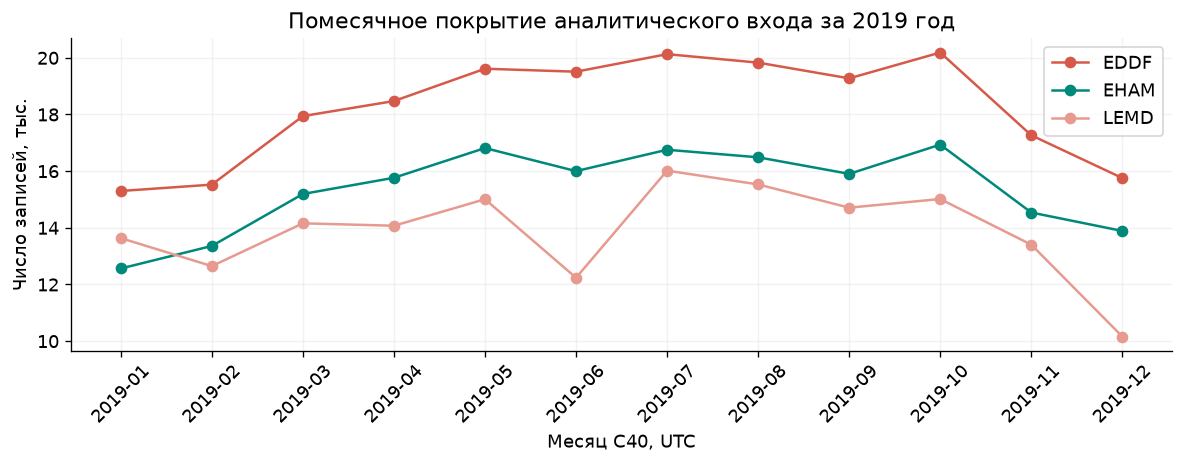

In [5]:
groups=counts.loc[counts.airport.isin(selected)&counts.month.isin(protocol['months'])].copy()
assert len(groups)==6
display(groups)
year=counts.loc[counts.airport.isin(selected)&counts.month.str.startswith('2019-')]
fig,ax=plt.subplots(figsize=(10,4))
for airport in selected:
    part=year.loc[year.airport.eq(airport)].sort_values('month')
    ax.plot(part.month,part.rows/1000,marker='o',label=airport)
ax.set(xlabel='Месяц C40, UTC',ylabel='Число записей, тыс.',title='Помесячное покрытие аналитического входа за 2019 год')
ax.tick_params(axis='x',rotation=45)
ax.legend()
save('12_expansion_monthly_input')


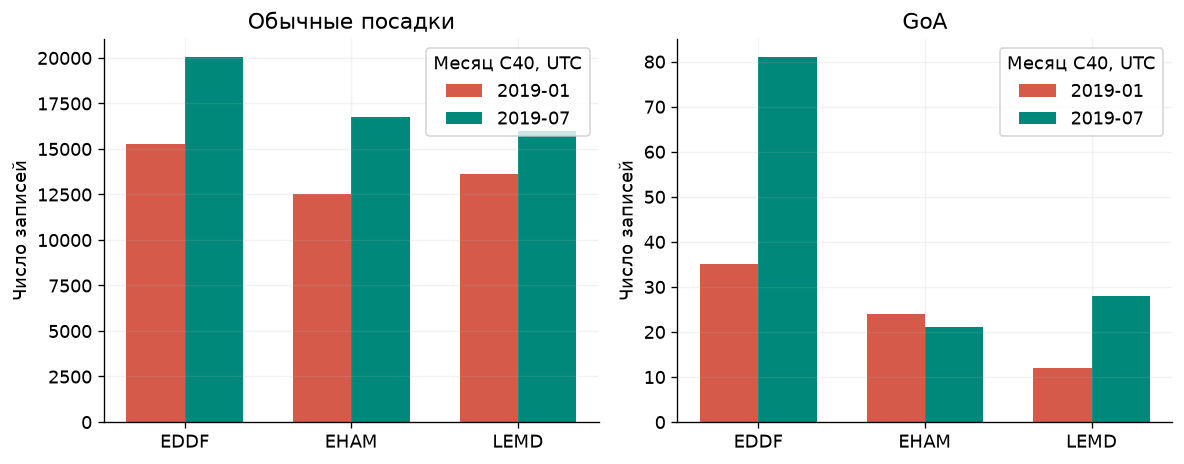

,airport,rows,go_arounds
0,EDDF,35423,116
1,EHAM,29313,45
2,LEMD,29648,40


In [6]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,label in zip(axes,[False,True]):
    for i,month in enumerate(protocol['months']):
        part=groups.loc[groups.month.eq(month)].set_index('airport').reindex(selected)
        values=part.go_arounds if label else part.rows-part.go_arounds
        ax.bar(np.arange(len(selected))+(i-.5)*.35,values,width=.35,label=month,color=[CORAL,GREEN][i])
    ax.set(xticks=np.arange(len(selected)),xticklabels=selected,ylabel='Число записей',title='GoA' if label else 'Обычные посадки')
    ax.legend(title='Месяц C40, UTC')
save('13_expansion_group_sizes')
display(pd.DataFrame([dict(airport=a,rows=int(g.rows.sum()),go_arounds=int(g.go_arounds.sum())) for a,g in groups.groupby('airport')]))


## 5. Правила загрузки, сопоставления и проверки

Планируется шесть запросов: три станции × два полных месяца. Каждый запрос
включает предшествующие сутки, routine и special, исходный текст METAR и UTC.
Сохраняются исходные байты, URL, SHA256 и время загрузки; дата наблюдения
не подменяется датой фактического получения сообщения.

Сопоставление: последнее наблюдение строго до C40, основной предел 60 минут,
чувствительность 30/90 минут. Разные тексты на одной отметке неоднозначны;
COR помечается отдельно. Повторный выбор при предполагаемой задержке
0/5/10/15 минут воспроизводит метод ноутбука 03. Качество не используется для
поиска более старого сообщения. Отсутствие погоды сохраняет исходную запись.

После загрузки проверяются единицы ветра и давления, коды видимости и облаков,
AUTO, COR, прогнозные группы, неизвестные токены и заполненность. Все
остаточные случаи учитываются; сомнительные значения автоматически не исправляются.
Проверка полного текста и основных полей остается раздельной.


In [7]:
display(pd.DataFrame([
    {'Проверка':'Отбор без частоты GoA','Статус':'Выполнено'},
    {'Проверка':'Метаданные трех станций и SHA256','Статус':'Выполнено'},
    {'Проверка':'Шесть групп по C40 UTC','Статус':'Выполнено'},
    {'Проверка':'Загрузка новых METAR','Статус':'Запланировано'},
    {'Проверка':'Покрытие, декодирование и остаточные случаи','Статус':'Запланировано'},
    {'Проверка':'Фактическая историческая доступность','Статус':'Не подтверждена'}]))
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==protocol['input_sha256']
assert protocol['metar_download_executed'] is False and protocol['training_executed'] is False


,Проверка,Статус
0,Отбор без частоты GoA,Выполнено
1,Метаданные трех станций и SHA256,Выполнено
2,Шесть групп по C40 UTC,Выполнено
3,Загрузка новых METAR,Запланировано
4,"Покрытие, декодирование и остаточные случаи",Запланировано
5,Фактическая историческая доступность,Не подтверждена
